# Deliverable 1

### Task 1: 
Sources used for 1
    - https://frost.met.no/python_example.html
    - Week 5 lecture

In [70]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [71]:
client_id = open("../frost_id/client_id.txt").read()

endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

r = requests.get(endpoint, parameters, auth=(client_id, ""))
assert r.status_code == 200

In [72]:
# Information about the request - Code taken from week 5 lecture

for name, value in r.headers.items():
    print(f"{name:16s}: {value}")

frost_payload = r.json()
print(f" \n{frost_payload.keys()}\n")

for f_name, f_value in frost_payload.items():
    if f_name == "data":
        continue
    print(f"{f_name:16s}: {f_value}")

# Creating a list with observations time and temperature
temp_data = [
    {
        "Time": pd.to_datetime(entry["referenceTime"]),
        "T_avg": entry["observations"][0]["value"]
    }
    for entry in frost_payload["data"]
    ]

# Converts list into dataframe and sets the time as index
T_data = pd.DataFrame.from_records(temp_data).set_index("Time")
T_data.columns

x-frost         : cache-status=hits:0/misses:0/noncacheable:1
cache-control   : max-age=-1
date            : Wed, 14 Oct 2026 07:05:26 GMT
content-type    : application/json
content-length  : 318967
 
dict_keys(['@context', '@type', 'apiVersion', 'license', 'createdAt', 'queryTime', 'currentItemCount', 'itemsPerPage', 'offset', 'totalItemCount', 'currentLink', 'data'])

@context        : https://frost.met.no/schema
@type           : ObservationResponse
apiVersion      : v0
license         : https://creativecommons.org/licenses/by/3.0/no/
createdAt       : 2026-10-14T07:05:26Z
queryTime       : 0.395
currentItemCount: 364
itemsPerPage    : 364
offset          : 0
totalItemCount  : 364
currentLink     : https://frost.met.no/observations/v0.jsonld?sources=SN17850&elements=mean%28air_temperature+P1D%29&referencetime=2025-01-01%2F2025-12-31


Index(['T_avg'], dtype='str')

##### Plotting of mean air temperature

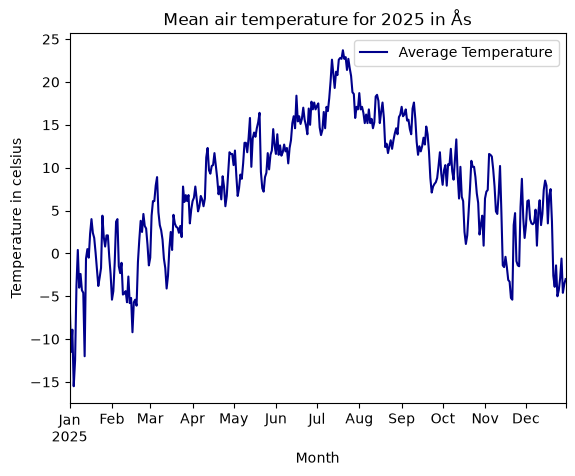

In [73]:
T_data.plot(
    y="T_avg",
    kind="line",
    color="darkblue",
    label="Average Temperature"
    )

plt.minorticks_off() # Only showing monthly ticks
plt.title("Mean air temperature for 2025 in Ås")
plt.xlabel("Month")
plt.ylabel("Temperature in celsius")
plt.show()

##### Discussion of plot:
For the first plot we've decided to use a line plot, simply because it is the most informative when looking at time series data of temperature.
A dark blue color have been chosen for high contrast. By using .minorticks_off() we've removed ticks that was difficult to see what was pointing to, only leaving us with ticks for each month. Otherwise, labels and titles have been named to give information about what the plot is about.

From the plot we can see that the highest average temperatures are in july and the coldes month january/february.



Summary table of temperature

In [74]:
summary_table = pd.DataFrame({
    "mean": T_data.mean(),
    "median": T_data.median(),
    "min": T_data.min(),
    "max": T_data.max()
    }).round(1)

# Rename T_avg
summary_table.index = ["Temperature (°C)"]

print(f"Average temperatures in Ås, 2025\n {'_' * 50}")
print(summary_table)

Average temperatures in Ås, 2025
 __________________________________________________
                  mean  median   min   max
Temperature (°C)   7.9     8.4 -15.5  23.7


##### Discussion of summary table:
Here we've made a data frame for the summary table, then found statistics by using corresponding statistic methods. We've decided using round to get all the statistics neat and similiar in decimals. 
From the statistics we get the yearly mean of 7.9 celsius, and the median is not too far off meaning we dont have outliers "breaking" the mean stat. (But would be more correctly to use median when describing this data without deeper statistical analysis)

### Task 2

### Task 3